# Legal Document Summarization

**Project:** Fine-tuning LLMs (BART / T5) to summarize legal documents (NDAs, SLAs) for
lawyer review, comparing extractive vs. abstractive approaches.

**This notebook covers:**
1. Downloading and loading the CUAD (Contract Understanding Atticus Dataset)
2. Exploratory data analysis — document lengths, clause category distribution
3. **Chunking**: splitting long contracts into model-sized, sentence-aligned chunks
4. **Named entity tagging**: extracting parties, dates, monetary amounts, and legal
   references from each chunk, for later clause/entity preservation checks
5. Saving a chunk-level dataset ready for the next stage: the LexRank extractive
   baseline and BART/T5 fine-tuning

## 1. Setup

In [2]:
import os
import re
import time
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import spacy

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

DATA_DIR = "cuad_data"
PROCESSED_DIR = "processed"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)

## 2. Download CUAD

CUAD (Contract Understanding Atticus Dataset) is a corpus of 510 commercial contracts,
manually labeled by legal experts across 41 clause categories (confidentiality,
indemnification, termination, governing law, etc.).

In [ ]:
CUAD_URL = "https://github.com/TheAtticusProject/cuad/raw/main/data.zip"
ZIP_PATH = os.path.join(DATA_DIR, "data.zip")
JSON_PATH = os.path.join(DATA_DIR, "CUADv1.json")

if not os.path.exists(JSON_PATH):
    print("Downloading CUAD data.zip ...")
    import urllib.request
    req = urllib.request.Request(CUAD_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=60) as r, open(ZIP_PATH, "wb") as f:
        f.write(r.read())
    import zipfile
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)
    print("Downloaded and extracted.")
else:
    print("CUADv1.json already present, skipping download.")

print(os.listdir(DATA_DIR))

CUADv1.json already present, skipping download.
['CUADv1.json', 'data.zip', 'test.json', 'train_separate_questions.json']


## 3. Load and inspect the raw structure

The JSON follows a SQuAD-style schema: `data` is a list of contracts, each with a
`title` and a single `paragraphs` entry holding the full `context` (the contract text)
and a list of 41 `qas` (question/answer pairs — one per clause category).


In [ ]:
import json

with open(JSON_PATH) as f:
    cuad_raw = json.load(f)

contracts = cuad_raw["data"]
print(f"CUAD version : {cuad_raw.get('version')}")
print(f"Number of contracts: {len(contracts)}")

sample = contracts[0]
print("\nSample contract title:", sample["title"])
print("Number of QAs (clause categories) per contract:", len(sample["paragraphs"][0]["qas"]))
print("\nFirst 500 characters of contract text:\n")
print(sample["paragraphs"][0]["context"][:500])

CUAD version : aok_v1.0
Number of contracts: 510

Sample contract title: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
Number of QAs (clause categories) per contract: 41

First 500 characters of contract text:

EXHIBIT 10.6

                              DISTRIBUTOR AGREEMENT

         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Company")  and Electric City of Illinois LLC ("Distributor") this 7th day of September, 1999.

                                    RECITALS

         A. The  Company's  Business.  The Company is  presently  engaged in the business  of selling an energy  efficiency  device,  which is  referred to as an 


In [ ]:
qas = sample["paragraphs"][0]["qas"]
for qa in qas[:5]:
    category = qa["id"].split("__")[-1]
    has_answer = not qa["is_impossible"]
    answer_text = qa["answers"][0]["text"] if has_answer and qa["answers"] else "(none found)"
    print(f"- {category:35s} | present: {has_answer!s:5} | e.g. '{answer_text[:80]}'")

- Document Name                       | present: True  | e.g. 'DISTRIBUTOR AGREEMENT'
- Parties                             | present: True  | e.g. 'Distributor'
- Agreement Date                      | present: True  | e.g. '7th day of September, 1999.'
- Effective Date                      | present: True  | e.g. 'The term of this  Agreement  shall be ten (10)                            years '
- Expiration Date                     | present: True  | e.g. 'The term of this  Agreement  shall be ten (10)                            years '


## 4. Flatten into a working dataframe

For the rest of the pipeline we mostly want two things per contract:
- the full contract text (our summarization *input*)
- the set of clause categories that are actually present, with their text spans

We flatten the nested JSON into two dataframes:
- `df_contracts`: one row per contract (title, full text, char/word length, category count)
- `df_clauses`: one row per (contract, clause category, span text) — only where a clause
  is present

In [6]:
contract_rows = []
clause_rows = []

for c in contracts:
    title = c["title"]
    para = c["paragraphs"][0]
    text = para["context"]

    present_categories = []
    for qa in para["qas"]:
        category = qa["id"].split("__")[-1]
        if not qa["is_impossible"] and qa["answers"]:
            present_categories.append(category)
            for ans in qa["answers"]:
                clause_rows.append({
                    "contract_title": title,
                    "clause_category": category,
                    "clause_text": ans["text"],
                    "answer_start": ans["answer_start"],
                })

    contract_rows.append({
        "contract_title": title,
        "char_length": len(text),
        "word_count": len(text.split()),
        "num_clause_categories_present": len(present_categories),
        "text": text,
    })

df_contracts = pd.DataFrame(contract_rows)
df_clauses = pd.DataFrame(clause_rows)

print("df_contracts:", df_contracts.shape)
print("df_clauses  :", df_clauses.shape)
df_contracts.drop(columns="text").head()

df_contracts: (510, 5)
df_clauses  : (13823, 4)


,contract_title,char_length,word_count,num_clause_categories_present
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT,54290,5998,19
1,"WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION AND DISTRIBUTION AGREEMENT",70383,11313,12
2,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_EX-10.16_Supply Agreement,11475,1880,6
3,CENTRACKINTERNATIONALINC_10_29_1999-EX-10.3-WEB SITE HOSTING AGREEMENT,15176,2280,10
4,NELNETINC_04_08_2020-EX-1-JOINT FILING AGREEMENT,1081,170,3


## 5. Exploratory Data Analysis (EDA)

### 5.1 Document length distribution
Legal contracts are long — this directly motivates the chunking strategy needed before feeding text into BART/T5.

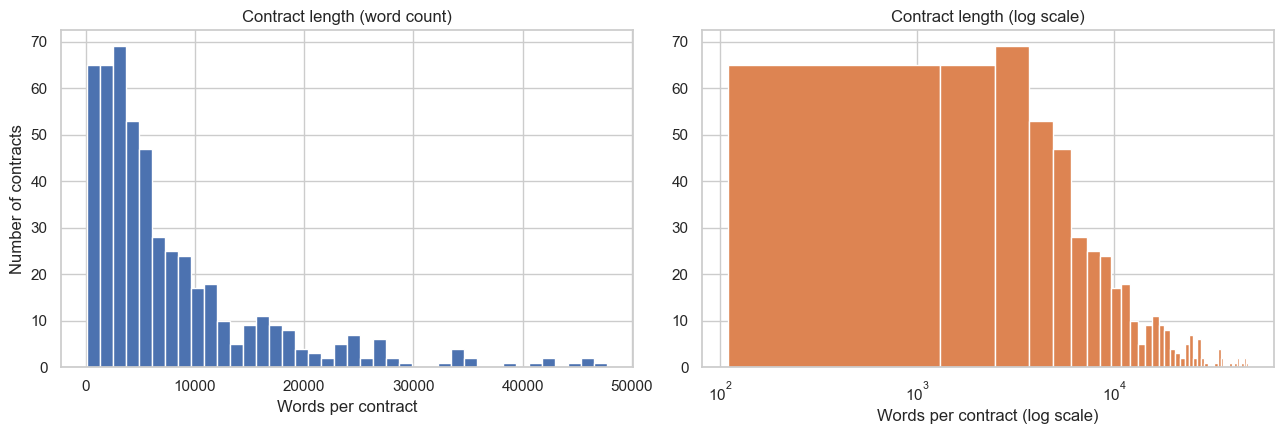

count      510.000000
mean      7861.188235
std       8367.292546
min        109.000000
25%       2457.000000
50%       5006.000000
75%      10196.250000
max      47733.000000
Name: word_count, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(df_contracts["word_count"], bins=40, color="#4C72B0", edgecolor="white")
axes[0].set_title("Contract length (word count)")
axes[0].set_xlabel("Words per contract")
axes[0].set_ylabel("Number of contracts")

axes[1].hist(df_contracts["word_count"], bins=40, color="#DD8452", edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Contract length (log scale)")
axes[1].set_xlabel("Words per contract (log scale)")

plt.tight_layout()
plt.show()

In [ ]:
approx_tokens = df_contracts["word_count"] / 0.75
pct_over_512 = (approx_tokens > 512).mean() * 100
pct_over_1024 = (approx_tokens > 1024).mean() * 100
print(f"Contracts with an estimated token count > 512  : {pct_over_512:.1f}%")
print(f"Contracts with an estimated token count > 1024 : {pct_over_1024:.1f}%")
print("\n-> The overwhelming majority of contracts exceed a single BART/T5 input window,")
print("confirming that a chunking strategy (not simple truncation) is needed.")

Contracts with an estimated token count > 512  : 96.5%
Contracts with an estimated token count > 1024 : 92.0%

-> The overwhelming majority of contracts exceed a single BART/T5 input window,
   confirming that a chunking strategy (not simple truncation) is needed.


### 5.2 Clause category coverage
Which clause types actually appear across the corpus? This tells us which categories are common enough to reliably evaluate clause preservation on (e.g. Governing Law, Parties), vs. rare ones (e.g. Most Favored Nation) that appear in only a handful of contracts.

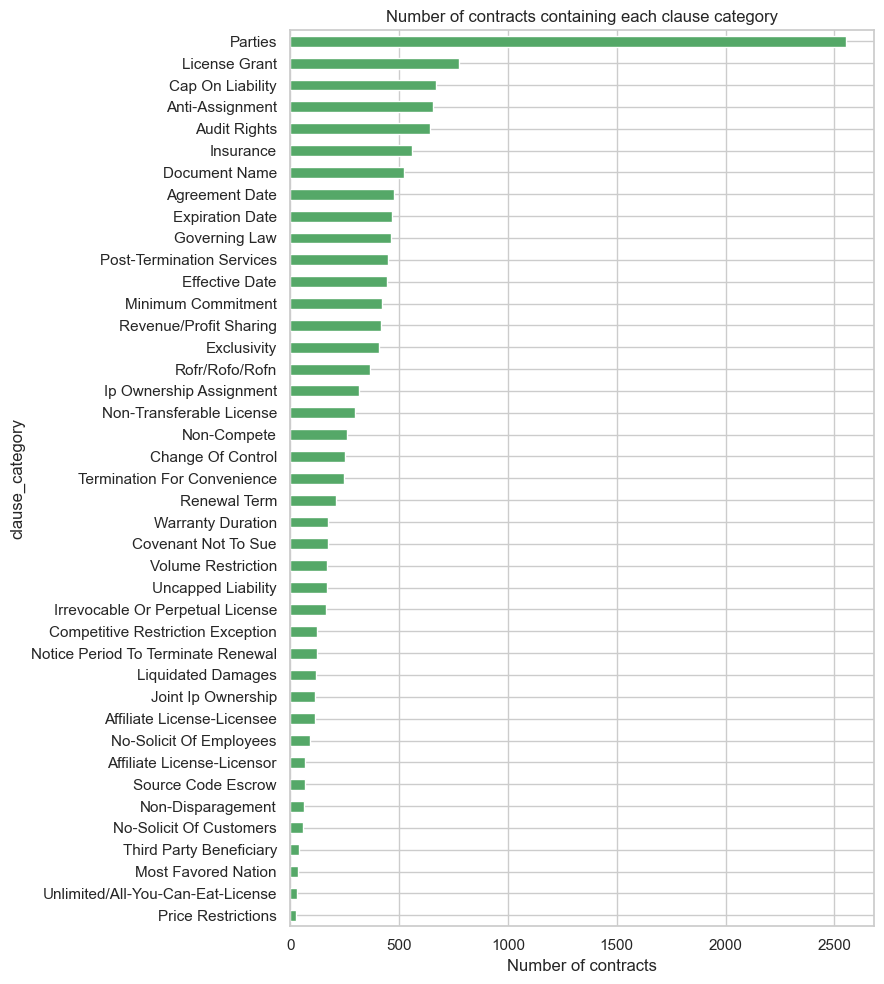

Top 10 most common clause categories:
clause_category
Parties             2554
License Grant        777
Cap On Liability     672
Anti-Assignment      654
Audit Rights         643
Insurance            560
Document Name        521
Agreement Date       476
Expiration Date      467
Governing Law        464
Name: count, dtype: int64


In [ ]:
category_counts = df_clauses["clause_category"].value_counts()

plt.figure(figsize=(9, 10))
category_counts.sort_values().plot(kind="barh", color="#55A868")
plt.title("Number of contracts containing each clause category")
plt.xlabel("Number of contracts")
plt.tight_layout()
plt.show()

print("Top 10 most common clause categories:")
print(category_counts.head(10))

### 5.3 How many clause categories appear per contract?
This matters for the 'clause preservation' evaluation later — contracts with more labeled clause types give us a richer check of whether the model's summary retains legally important content.

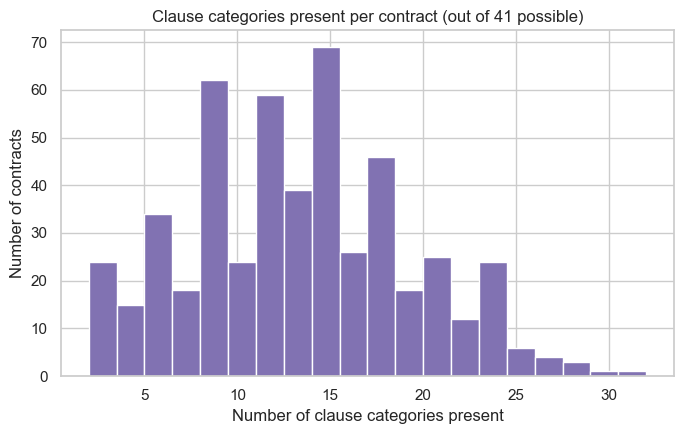

count    510.000000
mean      13.141176
std        5.912897
min        2.000000
25%        9.000000
50%       13.000000
75%       17.000000
max       32.000000
Name: num_clause_categories_present, dtype: float64


In [ ]:
plt.figure(figsize=(7, 4.5))
plt.hist(df_contracts["num_clause_categories_present"], bins=20, color="#8172B2", edgecolor="white")
plt.title("Clause categories present per contract (out of 41 possible)")
plt.xlabel("Number of clause categories present")
plt.ylabel("Number of contracts")
plt.tight_layout()
plt.show()

### 5.4 Spotlight: clauses most relevant to NDAs / SLAs

The project guidelines call out **confidentiality** and **indemnity** clauses
specifically. Checking CUAD's 41 category names directly below shows neither exact
label exists in this dataset — CUAD's schema uses different category names.

In [ ]:
all_categories = sorted(df_clauses["clause_category"].unique())
focus_categories = [c for c in all_categories if re.search(r"confidential|indemni", c, re.IGNORECASE)]

print(f"All {len(all_categories)} CUAD clause categories:")
for c in all_categories:
    print(f"  - {c}")

print(f"\nCategories matching 'confidential' or 'indemni': {focus_categories or '(none found)'}")
print("\n-> CUAD does not label 'Confidentiality' or 'Indemnification' as standalone")
print("categories. The closest available substitutes for the project's stated focus")
print("are: Cap On Liability, Uncapped Liability (indemnity-adjacent), and")
print("Non-Disparagement / Audit Rights (confidentiality-adjacent). We'll use these,")
print("plus the clearly present Governing Law / Termination For Convenience / Parties")
print("categories, as the priority clause set for reference-summary construction below.")

substitute_categories = ["Cap On Liability", "Uncapped Liability", "Non-Disparagement", "Audit Rights", "Governing Law", "Termination For Convenience"]
for c in substitute_categories:
    n = category_counts.get(c, 0)
    print(f"  {c:30s} -> present in {n} contracts")

All 41 CUAD clause categories:
  - Affiliate License-Licensee
  - Affiliate License-Licensor
  - Agreement Date
  - Anti-Assignment
  - Audit Rights
  - Cap On Liability
  - Change Of Control
  - Competitive Restriction Exception
  - Covenant Not To Sue
  - Document Name
  - Effective Date
  - Exclusivity
  - Expiration Date
  - Governing Law
  - Insurance
  - Ip Ownership Assignment
  - Irrevocable Or Perpetual License
  - Joint Ip Ownership
  - License Grant
  - Liquidated Damages
  - Minimum Commitment
  - Most Favored Nation
  - No-Solicit Of Customers
  - No-Solicit Of Employees
  - Non-Compete
  - Non-Disparagement
  - Non-Transferable License
  - Notice Period To Terminate Renewal
  - Parties
  - Post-Termination Services
  - Price Restrictions
  - Renewal Term
  - Revenue/Profit Sharing
  - Rofr/Rofo/Rofn
  - Source Code Escrow
  - Termination For Convenience
  - Third Party Beneficiary
  - Uncapped Liability
  - Unlimited/All-You-Can-Eat-License
  - Volume Restriction
  - Warr

## 6. Preprocessing: why chunking (not truncation)

Two ways to handle documents that exceed the model's input window:

- **Truncation**: just cut the document at N tokens. Simple, but silently throws away
  everything after the cutoff — for a 6,000-word contract, that can mean losing entire
  clauses (e.g. termination or indemnification, which often appear later in a contract).
- **Chunking** (what we do here): split the contract into overlapping, sentence-aligned
  pieces, each within the model's input limit. Each chunk gets summarized independently
  in the fine-tuning stage, and the chunk-summaries are then combined into a single document-level summary. This preserves content from the
  *entire* document, not just the first section.

**Design choices:**
- Split on **sentence boundaries** — never cut a sentence in half, since that produces
  garbled input to the model.
- Use a **word-count budget per chunk** (~380 words) for the model's token budget.
- Keep a small **sentence overlap** (2 sentences) between consecutive chunks, so a clause
  that starts near the end of one chunk isn't stripped of context in the next.

## 7. Sentence segmentation

We use a lightweight, rule-based spaCy `sentencizer` purely for sentence-boundary detection — it's fast enough to run over all 510 contracts in well under a minute.

In [ ]:
nlp_sent = spacy.blank("en")
nlp_sent.add_pipe("sentencizer")

def split_sentences(text):
    doc = nlp_sent(text)
    return [s.text.strip() for s in doc.sents if s.text.strip()]

# Quick check on one contract
sample_text = df_contracts["text"].iloc[0]
sample_sents = split_sentences(sample_text)
print(f"Sample contract: {len(sample_sents)} sentences")
for s in sample_sents[:3]:
    print(" -", s[:100])

Sample contract: 212 sentences
 - EXHIBIT 10.6

                              DISTRIBUTOR AGREEMENT

         THIS  DISTRIBUTOR  AGREE
 - RECITALS

         A. The  Company's  Business.
 - The Company is  presently  engaged in the business  of selling an energy  efficiency  device,  which


## 8. Chunking function

In [ ]:
def chunk_sentences(sentences, max_words=380, overlap_sentences=2):
    chunks = []
    current, current_words = [], 0
    i = 0
    while i < len(sentences):
        sent = sentences[i]
        n_words = len(sent.split())

        if current_words + n_words > max_words and current:
            chunks.append(" ".join(current))
            # start next chunk with overlap from the tail of the current one
            current = current[-overlap_sentences:] if overlap_sentences else []
            current_words = sum(len(s.split()) for s in current)

        current.append(sent)
        current_words += n_words
        i += 1

    if current:
        chunks.append(" ".join(current))
    return chunks


def chunk_contract(text, max_words=380, overlap_sentences=2):
    sentences = split_sentences(text)
    return chunk_sentences(sentences, max_words=max_words, overlap_sentences=overlap_sentences)


# Try it on the sample contract
sample_chunks = chunk_contract(sample_text)
print(f"Sample contract ({len(sample_text.split())} words) -> {len(sample_chunks)} chunks")
for i, c in enumerate(sample_chunks[:3]):
    print(f"\n--- Chunk {i} ({len(c.split())} words) ---")
    print(c[:220], "...")

Sample contract (5998 words) -> 21 chunks

--- Chunk 0 (364 words) ---
EXHIBIT 10.6

                              DISTRIBUTOR AGREEMENT

         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Company")  and Electric ...

--- Chunk 1 (352 words) ---
Distributor                            acknowledges that customers of other  distributors of                            the Products may have sites,  locations or operations                            in  the   Market,   ...

--- Chunk 2 (298 words) ---
All renewals of this  Agreement  shall be on the same                            terms and conditions as are set forth herein. 1.4      Company's Obligation. Company shall sell and deliver                            as   ...


### 8.1 Apply chunking to the full corpus (510 contracts)

In [ ]:
t0 = time.time()
chunk_rows = []

for _, row in df_contracts.iterrows():
    chunks = chunk_contract(row["text"], max_words=380, overlap_sentences=2)
    for i, chunk_text in enumerate(chunks):
        chunk_rows.append({
            "contract_title": row["contract_title"],
            "chunk_id": i,
            "num_chunks_in_contract": len(chunks),
            "chunk_text": chunk_text,
            "chunk_word_count": len(chunk_text.split()),
        })

df_chunks = pd.DataFrame(chunk_rows)
print(f"Chunked {df_contracts.shape[0]} contracts into {df_chunks.shape[0]} chunks in {time.time()-t0:.1f}s")
df_chunks.head()

Chunked 510 contracts into 15584 chunks in 63.3s


,contract_title,chunk_id,num_chunks_in_contract,chunk_text,chunk_word_count
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT,0,21,"EXHIBIT 10.6\n\n DISTRIBUTOR AGREEMENT\n\n THIS DISTRIBUTOR AGREEMENT (the ""...",364
1,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT,1,21,Distributor acknowledges that customers of other distributors of ...,352
2,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT,2,21,All renewals of this Agreement shall be on the same terms and conditions as are set for...,298
3,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT,3,21,"The Company may draw funds from the LC to pay for Distributor's purchases, which are not paid according to the te...",335
4,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT,4,21,"Thus, by way of example and not limitation, if there was an expectation of 50 in year one and 200 for year two and...",370


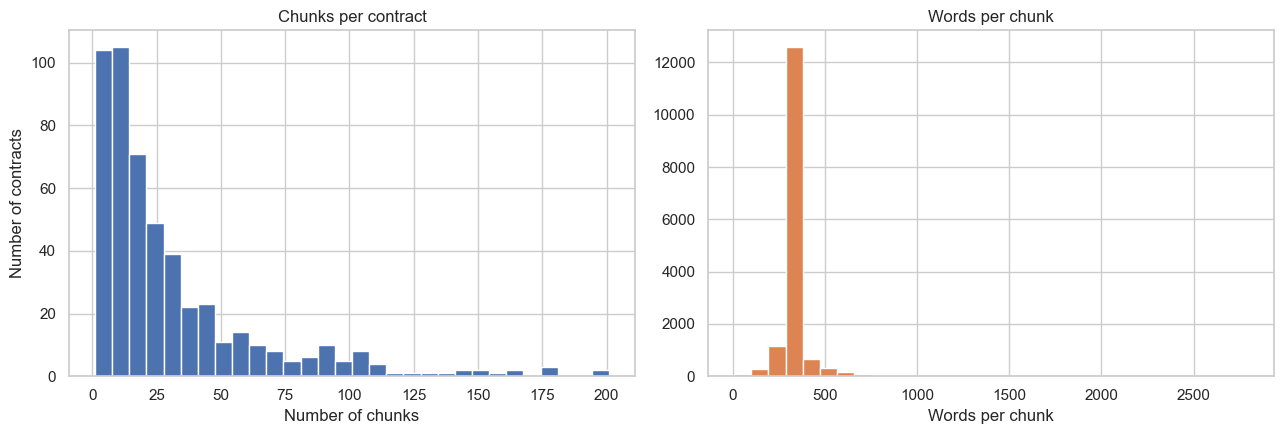

count    510.000000
mean      30.556863
std       34.351810
min        1.000000
25%        9.000000
50%       18.000000
75%       38.000000
max      201.000000
Name: chunk_id, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(df_chunks.groupby('contract_title')['chunk_id'].count(), bins=30, color='#4C72B0', edgecolor='white')
axes[0].set_title('Chunks per contract')
axes[0].set_xlabel('Number of chunks')
axes[0].set_ylabel('Number of contracts')

axes[1].hist(df_chunks['chunk_word_count'], bins=30, color='#DD8452', edgecolor='white')
axes[1].set_title('Words per chunk')
axes[1].set_xlabel('Words per chunk')

plt.tight_layout()
plt.show()

## 9. Named entity tagging

Legal summaries need to preserve *who* the parties are, *when* deadlines fall, and
*how much* money is involved — these are exactly the details a generative model can
accidentally drop or hallucinate. We tag each chunk with Spacy's NER so that later
(in evaluation) we can check: do the entities in the source chunk still appear in the
generated summary?

We restrict the pipeline to the `ner` component only (dropping the parser/tagger we
don't need) to keep this reasonably fast, and focus on entity types most relevant to
contracts: `ORG` (companies), `PERSON`, `DATE`, `MONEY`, `GPE` (jurisdictions/governing
law), `LAW`.


In [ ]:
nlp_ner = spacy.load("en_core_web_sm", disable=["parser", "tagger", "lemmatizer", "attribute_ruler"])

RELEVANT_LABELS = {"ORG", "PERSON", "DATE", "MONEY", "GPE", "LAW"}

def extract_entities(text):
    doc = nlp_ner(text)
    return [(ent.text, ent.label_) for ent in doc.ents if ent.label_ in RELEVANT_LABELS]

# Try it on one chunk
example_chunk = df_chunks["chunk_text"].iloc[0]
example_entities = extract_entities(example_chunk)
print(f"Chunk text (excerpt): {example_chunk[:200]}...\n")
print("Extracted entities:")
for text, label in example_entities[:15]:
    print(f"  [{label:6s}] {text}")

Chunk text (excerpt): EXHIBIT 10.6

                              DISTRIBUTOR AGREEMENT

         THIS  DISTRIBUTOR  AGREEMENT (the  "Agreement")  is made by and between Electric City Corp.,  a Delaware  corporation  ("Com...

Extracted entities:
  [ORG   ] DISTRIBUTOR AGREEMENT

         
  [ORG   ] DISTRIBUTOR  AGREEMENT
  [ORG   ] Electric City Corp.
  [GPE   ] Delaware
  [GPE   ] Electric City
  [DATE  ] this 7th day of September, 1999
  [ORG   ] Company
  [PERSON] Distributor
  [ORG   ] Objectives
  [ORG   ] Distributor
  [ORG   ] Company
  [ORG   ] the State of  Illinois
  [ORG   ] Distributor as Company's
  [PERSON] Distributor
  [ORG   ] the                            Market


### 9.1 Run NER over a sample of contracts

In [ ]:
SAMPLE_SIZE = 20
sample_titles = df_contracts["contract_title"].iloc[:SAMPLE_SIZE].tolist()
mask = df_chunks["contract_title"].isin(sample_titles)

t0 = time.time()
df_chunks["entities"] = None
df_chunks.loc[mask, "entities"] = df_chunks.loc[mask, "chunk_text"].apply(extract_entities)
elapsed = time.time() - t0

n_chunks_processed = mask.sum()
print(f"Ran NER on {n_chunks_processed} chunks from {SAMPLE_SIZE} contracts in {elapsed:.1f}s "
      f"({elapsed/max(n_chunks_processed,1):.2f}s/chunk)")
print(f"Estimated time for the full corpus ({len(df_chunks)} chunks): "
      f"~{elapsed/max(n_chunks_processed,1)*len(df_chunks)/60:.1f} minutes")

Ran NER on 527 chunks from 20 contracts in 67.1s (0.13s/chunk)
Estimated time for the full corpus (15584 chunks): ~33.0 minutes


In [ ]:
# What kinds of entities show up most often across the sample?
all_entities = [e for ents in df_chunks.loc[mask, "entities"] for e in ents]
label_counts = Counter(label for _, label in all_entities)

print("Entity type counts (sample of 20 contracts):")
for label, count in label_counts.most_common():
    print(f"  {label:6s}: {count}")

# A few example organizations and dates found
orgs = [text for text, label in all_entities if label == "ORG"]
dates = [text for text, label in all_entities if label == "DATE"]
print("\nExample ORG entities:", orgs[:8])
print("Example DATE entities:", dates[:8])

Entity type counts (sample of 20 contracts):
  ORG   : 7099
  PERSON: 1857
  LAW   : 990
  DATE  : 924
  GPE   : 570
  MONEY : 85

Example ORG entities: ['DISTRIBUTOR AGREEMENT\n\n         ', 'DISTRIBUTOR  AGREEMENT', 'Electric City Corp.', 'Company', 'Objectives', 'Distributor', 'Company', 'the State of  Illinois']
Example DATE entities: ['this 7th day of September, 1999', '10)                            years', 'annual', '2) month', 'the first of each month', '12) month  period', 'the first Product Year', '1999']


## 10. Save the processed datasets

Save both the contract-level and chunk-level dataframes so they're on disk (in
`processed/`).

In [ ]:
df_contracts.to_pickle(os.path.join(PROCESSED_DIR, "cuad_contracts.pkl"))
df_clauses.to_pickle(os.path.join(PROCESSED_DIR, "cuad_clauses.pkl"))
df_chunks.to_pickle(os.path.join(PROCESSED_DIR, "cuad_chunks.pkl"))

print("Saved:")
print(f"  {PROCESSED_DIR}/cuad_contracts.pkl -> {df_contracts.shape}")
print(f"  {PROCESSED_DIR}/cuad_clauses.pkl   -> {df_clauses.shape}")
print(f"  {PROCESSED_DIR}/cuad_chunks.pkl    -> {df_chunks.shape}")

Saved:
  processed/cuad_contracts.pkl -> (510, 5)
  processed/cuad_clauses.pkl   -> (13823, 4)
  processed/cuad_chunks.pkl    -> (15584, 6)


## 11. Extractive baseline: LexRank

Before fine-tuning BART/T5 (abstractive), we build the **extractive** comparison: LexRank.

**How LexRank works:**
1. Split the document into sentences.
2. Represent each sentence as a TF-IDF vector.
3. Build a sentence-similarity graph — an edge weight between two sentences is their
   cosine similarity.
4. Run **PageRank** over that graph: a sentence that is similar to many other important
   sentences gets a high centrality score.
5. Take the top-N highest-scoring sentences as the summary, re-ordered back into their
   original position in the document so the summary reads coherently.

**Why this matters as a baseline:** LexRank only *selects* existing sentences —
it can't paraphrase, merge information across sentences, or shorten a clause while
preserving its meaning, but it also can't hallucinate or drop clauses due to an input
length limit (it scores every sentence in the document directly, no chunking needed).

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import networkx as nx

def lexrank_summarize(text, num_sentences=5, min_sentence_words=4):
    sentences = split_sentences(text)
    sentences = [s for s in sentences if len(s.split()) >= min_sentence_words]

    if len(sentences) <= num_sentences:
        return sentences

    vectorizer = TfidfVectorizer(stop_words="english")
    tfidf = vectorizer.fit_transform(sentences)
    similarity = cosine_similarity(tfidf)
    np.fill_diagonal(similarity, 0)

    graph = nx.from_numpy_array(similarity)
    scores = nx.pagerank(graph, max_iter=200)

    top_idx = sorted(scores, key=scores.get, reverse=True)[:num_sentences]
    top_idx.sort()
    return [sentences[i] for i in top_idx]


# Try it on the sample contract
extractive_sample = lexrank_summarize(sample_text, num_sentences=5)
print(f"LexRank summary of sample contract ({len(extractive_sample)} sentences):\n")
for i, s in enumerate(extractive_sample, 1):
    print(f"{i}. {s[:220]}{'...' if len(s) > 220 else ''}\n")

LexRank summary of sample contract (5 sentences):

1. The Company appoints the Distributor as an  exclusive  distributor  of Products in the Market,  subject to the terms and conditions of this Agreement.

2. Company  hereby   appoints                            Distributor as Company's exclusive distributor within                            the Market and grants to  Distributor  the  exclusive                            righ...

3. The Distributor shall order Products from the Company                   on a purchase  order form  mutually  acceptable to the Company                   and Distributor and which is consistent with Exhibit B hereto,     ...

4. In addition to any other remedy                   which this Agreement provides to Distributor  against Company,                   if Company fails to deliver or delays in  delivering  Products                   as were ...

5. The terms  pursuant  to which  such  other                   Products  or devices  shall be sold by Company

### 11.1 Apply LexRank across the full corpus

In [ ]:
t0 = time.time()
extractive_rows = []

for _, row in df_contracts.iterrows():
    summary_sentences = lexrank_summarize(row["text"], num_sentences=5)
    summary_text = " ".join(summary_sentences)
    extractive_rows.append({
        "contract_title": row["contract_title"],
        "extractive_summary": summary_text,
        "extractive_summary_word_count": len(summary_text.split()),
        "original_word_count": row["word_count"],
    })

df_extractive = pd.DataFrame(extractive_rows)
df_extractive["compression_ratio"] = (df_extractive["extractive_summary_word_count"] / df_extractive["original_word_count"])

print(f"Generated LexRank summaries for {len(df_extractive)} contracts in {time.time()-t0:.1f}s")
df_extractive.head()

Generated LexRank summaries for 510 contracts in 113.9s


,contract_title,extractive_summary,extractive_summary_word_count,original_word_count,compression_ratio
0,LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT,"The Company appoints the Distributor as an exclusive distributor of Products in the Market, subject to the terms...",270,5998,0.045015
1,"WHITESMOKE,INC_11_08_2011-EX-10.26-PROMOTION AND DISTRIBUTION AGREEMENT","Subject to the terms and conditions of this Agreement, Google grants to Distributor a [* ] license during the Term ...",634,11313,0.056042
2,LohaCompanyltd_20191209_F-1_EX-10.16_11917878_EX-10.16_Supply Agreement,"Specific order: The products quantity, unit price, specifications, delivery time and transportation, specific conten...",170,1880,0.090426
3,CENTRACKINTERNATIONALINC_10_29_1999-EX-10.3-WEB SITE HOSTING AGREEMENT,"The term ""Hosted Site"" shall mean the Web site of the Customer that is hosted by i-on under the terms and conditions...",103,2280,0.045175
4,NELNETINC_04_08_2020-EX-1-JOINT FILING AGREEMENT,Exhibit 1\n\nJOINT FILING AGREEMENT\n\nThe undersigned hereby agree to jointly prepare and file with the applicable ...,170,170,1.000000


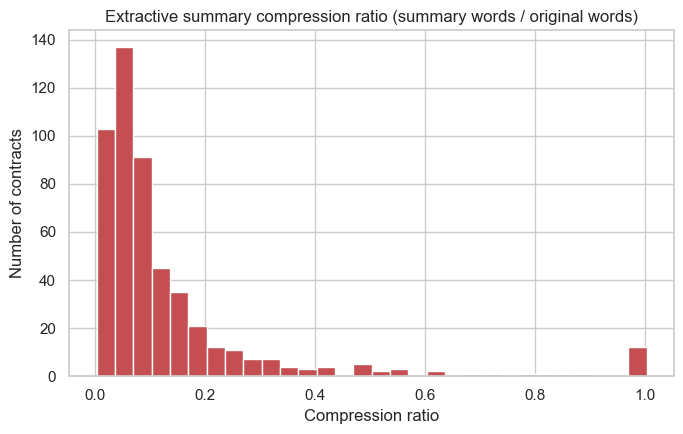

count    510.000000
mean       0.134671
std        0.184937
min        0.003392
25%        0.042607
50%        0.074931
75%        0.140824
max        1.003175
Name: compression_ratio, dtype: float64
count     510.000000
mean      470.366667
std       435.281199
min        20.000000
25%       224.000000
50%       350.500000
75%       558.250000
max      3558.000000
Name: extractive_summary_word_count, dtype: float64


In [ ]:
plt.figure(figsize=(7, 4.5))
plt.hist(df_extractive["compression_ratio"], bins=30, color="#C44E52", edgecolor="white")
plt.title("Extractive summary compression ratio (summary words / original words)")
plt.xlabel("Compression ratio")
plt.ylabel("Number of contracts")
plt.tight_layout()
plt.show()

### 11.2 Quick check: clause preservation

A rough, quick check: for one contract, does its
LexRank summary happen to contain any of the expert-labeled clause spans from
`df_clauses`?

In [ ]:
check_title = df_contracts["contract_title"].iloc[0]
check_summary = df_extractive.loc[df_extractive["contract_title"] == check_title, "extractive_summary"].iloc[0]
check_clauses = df_clauses[df_clauses["contract_title"] == check_title]

print(f"Contract: {check_title}")
print(f"Labeled clause categories: {len(check_clauses)}\n")

for _, clause_row in check_clauses.iterrows():
    snippet = clause_row["clause_text"][:60].strip()
    found = snippet in check_summary if len(snippet) > 10 else False
    print(f"  [{'x' if found else ' '}] {clause_row['clause_category']}")

Contract: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
Labeled clause categories: 46

  [ ] Document Name
  [x] Parties
  [ ] Parties
  [ ] Parties
  [ ] Parties
  [ ] Parties
  [ ] Agreement Date
  [ ] Effective Date
  [ ] Effective Date
  [ ] Expiration Date
  [ ] Renewal Term
  [ ] Governing Law
  [ ] Exclusivity
  [x] Exclusivity
  [x] Exclusivity
  [ ] No-Solicit Of Customers
  [ ] No-Solicit Of Customers
  [ ] No-Solicit Of Employees
  [ ] Rofr/Rofo/Rofn
  [ ] Rofr/Rofo/Rofn
  [ ] Rofr/Rofo/Rofn
  [ ] Anti-Assignment
  [ ] Anti-Assignment
  [ ] Price Restrictions
  [ ] Price Restrictions
  [ ] Minimum Commitment
  [ ] Minimum Commitment
  [ ] Minimum Commitment
  [ ] Minimum Commitment
  [ ] Minimum Commitment
  [x] License Grant
  [ ] License Grant
  [ ] Post-Termination Services
  [ ] Post-Termination Services
  [ ] Post-Termination Services
  [ ] Post-Termination Services
  [ ] Warranty Duration
  [ ] Warranty Duration
  [ ] Warranty Duration
  [ ] Warranty Duration
  [

## 12. Save the extractive baseline results

In [ ]:
df_extractive.to_pickle(os.path.join(PROCESSED_DIR, "cuad_extractive_summaries.pkl"))
print(f"Saved {PROCESSED_DIR}/cuad_extractive_summaries.pkl -> {df_extractive.shape}")

Saved processed/cuad_extractive_summaries.pkl -> (510, 5)


## 13. Constructing reference summaries for fine-tuning & evaluation

In [ ]:
PRIORITY_CATEGORIES = [
    "Document Name", "Parties", "Agreement Date", "Effective Date", "Expiration Date",
    "Renewal Term", "Termination For Convenience", "Governing Law", "Exclusivity",
    "Non-Compete", "License Grant", "Cap On Liability", "Uncapped Liability",
    "Audit Rights", "Insurance", "Ip Ownership Assignment",
]

def build_reference_summary(contract_title, max_words=150):
    rows = df_clauses[df_clauses["contract_title"] == contract_title]
    by_category = {r["clause_category"]: r["clause_text"] for _, r in rows.iterrows()}

    ordered_categories = [c for c in PRIORITY_CATEGORIES if c in by_category]
    ordered_categories += [c for c in by_category if c not in ordered_categories]

    pieces, word_count = [], 0
    for category in ordered_categories:
        text = re.sub(r"\s+", " ", by_category[category]).strip()
        n_words = len(text.split())
        if word_count + n_words > max_words and pieces:
            break
        pieces.append(text)
        word_count += n_words

    return " ".join(pieces)


# Try it on the sample contract
sample_reference = build_reference_summary(df_contracts["contract_title"].iloc[0])
print(f"Reference summary ({len(sample_reference.split())} words):\n")
print(sample_reference)

Reference summary (144 words):

DISTRIBUTOR AGREEMENT Electric City of Illinois LLC 7th day of September, 1999. Unless earlier terminated otherwise provided therein, this Agreement, subject to the commencement date established in Section 1.3, shall be effective immediately. The term of this Agreement shall be ten (10) years (the "Term") which shall commence on the date upon which the Company delivers to Distributor the last Sample, as defined hereinafter. If Distributor complies with all of the terms of this Agreement, the Agreement shall be renewable on an annual basis for one (1) year terms for up to another ten (10) years on the same terms and conditions as set forth herein. This Agreement is to be construed according to the laws of the State of Illinois. The Company appoints the Distributor as an exclusive distributor of Products in the Market, subject to the terms and conditions of this Agreement.


In [ ]:
t0 = time.time()
df_contracts["reference_summary"] = df_contracts["contract_title"].apply(build_reference_summary)
df_contracts["reference_summary_word_count"] = df_contracts["reference_summary"].str.split().str.len()

print(f"Built reference summaries for {len(df_contracts)} contracts in {time.time()-t0:.1f}s")
print(df_contracts["reference_summary_word_count"].describe())

# Flag contracts with an unusually short reference
thin_reference = df_contracts[df_contracts["reference_summary_word_count"] < 20]
print(f"\nContracts with a very thin reference summary (<20 words): {len(thin_reference)}")

Built reference summaries for 510 contracts in 2.1s
count    510.000000
mean     109.901961
std       37.466399
min        7.000000
25%       95.250000
50%      121.000000
75%      138.000000
max      150.000000
Name: reference_summary_word_count, dtype: float64

Contracts with a very thin reference summary (<20 words): 29


## 14. Building the Hugging Face `Dataset` and train/val/test split

We use the `datasets` library to package (source text, reference summary) pairs into
train/validation/test splits, ready for `Seq2SeqTrainer` in the fine-tuning stage.

In [ ]:
from datasets import Dataset, DatasetDict

hf_df = df_contracts[["contract_title", "text", "reference_summary"]].rename(columns={"text": "source_text", "reference_summary": "target_summary"})

full_dataset = Dataset.from_pandas(hf_df, preserve_index=False)

# 80 / 10 / 10 split
split_1 = full_dataset.train_test_split(test_size=0.2, seed=42)
split_2 = split_1["test"].train_test_split(test_size=0.5, seed=42)

dataset = DatasetDict({
    "train": split_1["train"],
    "validation": split_2["train"],
    "test": split_2["test"],
})

print(dataset)
print("\nExample record keys:", dataset["train"][0].keys())

c:\Users\Rahul\OneDrive\Desktop\ML_Day1\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


DatasetDict({
    train: Dataset({
        features: ['contract_title', 'source_text', 'target_summary'],
        num_rows: 408
    })
    validation: Dataset({
        features: ['contract_title', 'source_text', 'target_summary'],
        num_rows: 51
    })
    test: Dataset({
        features: ['contract_title', 'source_text', 'target_summary'],
        num_rows: 51
    })
})

Example record keys: dict_keys(['contract_title', 'source_text', 'target_summary'])


In [ ]:
DATASET_DIR = os.path.join(PROCESSED_DIR, "hf_dataset")
dataset.save_to_disk(DATASET_DIR)
print(f"Saved Hugging Face DatasetDict to {DATASET_DIR}")

Saving the dataset (1/1 shards): 100%|██████████| 51/51 [00:00<00:00, 2678.79 examples/s]

Saved Hugging Face DatasetDict to processed\hf_dataset


## 15. Fine-tuning BART and T5

We fine-tune two models for the extractive-vs-abstractive comparison the project asks
for:
- `facebook/bart-base` (BART)
- `t5-base` (T5)


In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    DataCollatorForSeq2Seq,
)
from datasets import load_from_disk
import torch

MODEL_NAME = "t5-base"
IS_T5 = "t5" in MODEL_NAME
MAX_INPUT_LENGTH = 512
MAX_TARGET_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)

dataset = load_from_disk("processed/hf_dataset")


def preprocess(batch):
    inputs = batch["source_text"]
    if IS_T5:
        inputs = ["summarize: " + t for t in inputs]
    model_inputs = tokenizer(inputs, max_length=MAX_INPUT_LENGTH, truncation=True)
    labels = tokenizer(text_target=batch["target_summary"], max_length=MAX_TARGET_LENGTH, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs


tokenized = dataset.map(preprocess, batched=True, remove_columns=dataset["train"].column_names)
data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

In [ ]:
training_args = Seq2SeqTrainingArguments(
    output_dir=f"./checkpoints/{MODEL_NAME.replace('/', '_')}",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=2,
    num_train_epochs=2,
    weight_decay=0.01,
    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LENGTH,
    fp16=False,
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=data_collator,
    tokenizer=tokenizer,
)

trainer.train()
trainer.save_model(f"./final_model/{MODEL_NAME.replace('/', '_')}")
tokenizer.save_pretrained(f"./final_model/{MODEL_NAME.replace('/', '_')}")

## 16. Hierarchical inference: summarize chunks, then combine

For documents longer than the model's input window, we don't summarize the whole
contract in one call — we summarize each **chunk** independently, then
combine the chunk-summaries into one document-level summary.

In [ ]:
def chunk_summarizer_stub(chunk_text, num_sentences=2):
    return " ".join(lexrank_summarize(chunk_text, num_sentences=num_sentences))


def summarize_contract_hierarchical(contract_title, summarizer_fn=chunk_summarizer_stub, recombine_if_words_over=250):
    contract_chunks = df_chunks[df_chunks["contract_title"] == contract_title].sort_values("chunk_id")
    chunk_summaries = [summarizer_fn(row["chunk_text"]) for _, row in contract_chunks.iterrows()]
    combined = " ".join(chunk_summaries)

    if len(combined.split()) > recombine_if_words_over:
        combined = summarizer_fn(combined, num_sentences=5)

    return combined, chunk_summaries

demo_title = df_contracts["contract_title"].iloc[0]
final_summary, per_chunk_summaries = summarize_contract_hierarchical(demo_title)

print(f"Contract: {demo_title}")
print(f"Number of chunks summarized: {len(per_chunk_summaries)}")
print(f"\nFinal hierarchical summary ({len(final_summary.split())} words):\n")
print(final_summary[:800])

Contract: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
Number of chunks summarized: 21

Final hierarchical summary (115 words):

The  Distributor  shall  not order or                   purchase Products from any source other than the Company. The  Distributor  shall  not order or                   purchase Products from any source other than the Company. Except for the  Improved  Products  for which the  Distributor                   receives the Annual  Notice,  the Company  shall sell Improved                   Products  to   Distributor   only  with  the  consent  of  the                   Distributor. Except for the  Improved  Products  for which the  Distributor                   receives the Annual  Notice,  the Company  shall sell Improved                   Products  to   Distributor   only  with  the  consent  of  the                   Distributor. Repurchased  Products  shall be                   shipped at


## 17. ROUGE evaluation

We compute ROUGE-1 / ROUGE-2 / ROUGE-L between each candidate summary and the reference
summary.

In [ ]:
from rouge_score import rouge_scorer

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def score_summaries(df, candidate_col, reference_col="reference_summary"):
    records = []
    for _, row in df.iterrows():
        scores = scorer.score(row[reference_col], row[candidate_col])
        records.append({
            "contract_title": row["contract_title"],
            "rouge1_f": scores["rouge1"].fmeasure,
            "rouge2_f": scores["rouge2"].fmeasure,
            "rougeL_f": scores["rougeL"].fmeasure,
        })
    return pd.DataFrame(records)

eval_df = df_extractive.merge(df_contracts[["contract_title", "reference_summary"]], on="contract_title")
rouge_results = score_summaries(eval_df, candidate_col="extractive_summary")

print("LexRank extractive baseline vs. reference summaries -- ROUGE F1 (mean over 510 contracts):")
print(rouge_results[["rouge1_f", "rouge2_f", "rougeL_f"]].mean())

LexRank extractive baseline vs. reference summaries -- ROUGE F1 (mean over 510 contracts):
rouge1_f    0.258707
rouge2_f    0.100919
rougeL_f    0.160954
dtype: float64


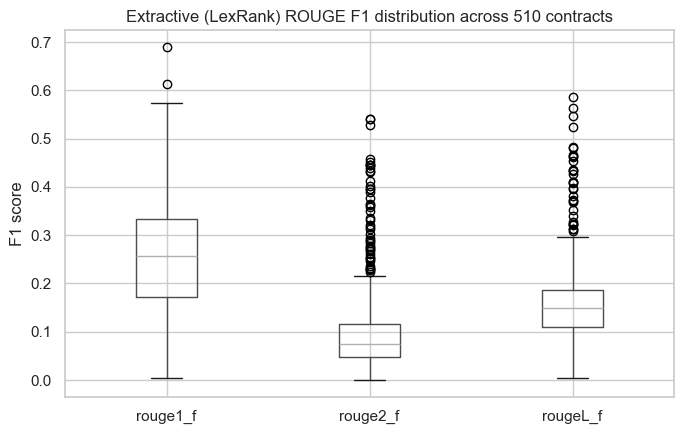

Saved processed/rouge_extractive_baseline.pkl -> (510, 4)


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
rouge_results[["rouge1_f", "rouge2_f", "rougeL_f"]].boxplot(ax=ax)
ax.set_title("Extractive (LexRank) ROUGE F1 distribution across 510 contracts")
ax.set_ylabel("F1 score")
plt.tight_layout()
plt.show()

rouge_results.to_pickle(os.path.join(PROCESSED_DIR, "rouge_extractive_baseline.pkl"))
print(f"Saved {PROCESSED_DIR}/rouge_extractive_baseline.pkl -> {rouge_results.shape}")

## 18. Save updated contract-level data

In [ ]:
df_contracts.to_pickle(os.path.join(PROCESSED_DIR, "cuad_contracts.pkl"))
print(f"Saved {PROCESSED_DIR}/cuad_contracts.pkl -> {df_contracts.shape} (added reference_summary column)")

Saved processed/cuad_contracts.pkl -> (510, 7) (added reference_summary column)


## 19. Clause preservation scoring

**Method:** for each labeled clause span, strip stopwords and compare its remaining
content words against the candidate summary's content words. The **recall** (fraction
of the clause's content words that appear somewhere in the summary) is our per-clause
preservation score; a clause counts as "preserved" if that recall is >= 0.5.

In [ ]:
from spacy.lang.en.stop_words import STOP_WORDS

def normalize_words(text):
    words = re.findall(r"[a-zA-Z]+", text.lower())
    return {w for w in words if w not in STOP_WORDS and len(w) > 2}

def clause_preservation_score(clause_text, summary_text):
    clause_words = normalize_words(clause_text)
    if not clause_words:
        return None
    summary_words = normalize_words(summary_text)
    return len(clause_words & summary_words) / len(clause_words)


def contract_clause_preservation(contract_title, summary_text, threshold=0.5):
    rows = df_clauses[df_clauses["contract_title"] == contract_title]
    if rows.empty:
        return np.nan, 0
    scores = [clause_preservation_score(r["clause_text"], summary_text) for _, r in rows.iterrows()]
    scores = [s for s in scores if s is not None]
    if not scores:
        return np.nan, 0
    preserved = sum(1 for s in scores if s >= threshold)
    return preserved / len(scores), len(scores)


# Try it on the sample contract's LexRank summary
demo_row = df_extractive[df_extractive["contract_title"] == demo_title].iloc[0]
rate, n_checked = contract_clause_preservation(demo_title, demo_row["extractive_summary"])
print(f"Contract: {demo_title}")
print(f"Clause preservation rate: {rate:.1%} ({n_checked} labeled clauses checked)")

Contract: LIMEENERGYCO_09_09_1999-EX-10-DISTRIBUTOR AGREEMENT
Clause preservation rate: 39.1% (46 labeled clauses checked)


### 19.1 Apply across the full corpus

In [ ]:
t0 = time.time()
preservation_rows = []
for _, row in df_extractive.iterrows():
    rate, n_checked = contract_clause_preservation(row["contract_title"], row["extractive_summary"])
    preservation_rows.append({
        "contract_title": row["contract_title"],
        "clause_preservation_rate": rate,
        "num_clauses_checked": n_checked,
    })

df_preservation = pd.DataFrame(preservation_rows)
print(f"Scored clause preservation for {len(df_preservation)} contracts in {time.time()-t0:.1f}s")
print(df_preservation["clause_preservation_rate"].describe())

Scored clause preservation for 510 contracts in 6.7s
count    510.000000
mean       0.438826
std        0.234195
min        0.000000
25%        0.260870
50%        0.400000
75%        0.577564
max        1.000000
Name: clause_preservation_rate, dtype: float64


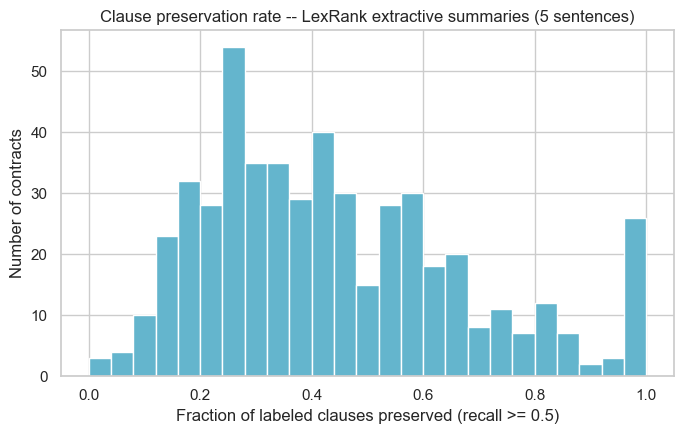

Saved processed/clause_preservation_extractive.pkl -> (510, 3)


In [ ]:
plt.figure(figsize=(7, 4.5))
plt.hist(df_preservation["clause_preservation_rate"].dropna(), bins=25, color="#64B5CD", edgecolor="white")
plt.title("Clause preservation rate -- LexRank extractive summaries (5 sentences)")
plt.xlabel("Fraction of labeled clauses preserved (recall >= 0.5)")
plt.ylabel("Number of contracts")
plt.tight_layout()
plt.show()

df_preservation.to_pickle(os.path.join(PROCESSED_DIR, "clause_preservation_extractive.pkl"))
print(f"Saved {PROCESSED_DIR}/clause_preservation_extractive.pkl -> {df_preservation.shape}")

## 20. Summarize & validate 10 contracts

We select 10 contracts spanning a range of lengths (not just the first 10), so the
validation set isn't biased toward unusually short or long documents.

In [ ]:
# Pick 10 contracts spread across the length distribution (short to long)
length_sorted = df_contracts.sort_values("word_count").reset_index(drop=True)
sample_positions = np.linspace(0, len(length_sorted) - 1, 10).astype(int)
validation_titles = length_sorted.loc[sample_positions, "contract_title"].tolist()

print("Selected 10 contracts for final validation (spread by length):")
for t in validation_titles:
    wc = df_contracts.loc[df_contracts["contract_title"] == t, "word_count"].iloc[0]
    print(f"  ({wc:>6} words)  {t}")

Selected 10 contracts for final validation (spread by length):
  (   109 words)  RMRGROUPINC_01_22_2020-EX-99.1-JOINT FILING AGREEMENT
  (  1088 words)  DRAGONSYSTEMSINC_01_08_1999-EX-10.17-OUTSOURCING AGREEMENT
  (  2297 words)  VgrabCommunicationsInc_20200129_10-K_EX-10.33_11958828_EX-10.33_Development Agreement
  (  3037 words)  FLOTEKINDUSTRIESINCCN_05_09_2019-EX-10.1-SUPPLY AGREEMENT
  (  4170 words)  QIWI_06_16_2017-EX-99.(D)(2)-COOPERATION AGREEMENT
  (  5760 words)  RUBIOSRESTAURANTSINC_03_31_2008-EX-10.75-SPONSORSHIP AGREEMENT
  (  7749 words)  SFGFINANCIALCORP_05_12_2009-EX-10.1-SOFTWARE LICENSE AND MAINTENANCE AGREEMENT
  ( 10958 words)  WPPPLC_04_30_2020-EX-4.28-SERVICE AGREEMENT
  ( 17703 words)  PHREESIA,INC_05_28_2019-EX-10.18-STRATEGIC ALLIANCE AGREEMENT
  ( 47733 words)  GOOSEHEADINSURANCE,INC_04_02_2018-EX-10.6-Franchise Agreement


In [ ]:
validation_rows = []
for title in validation_titles:
    candidate_summary, _ = summarize_contract_hierarchical(title)
    reference = df_contracts.loc[df_contracts["contract_title"] == title, "reference_summary"].iloc[0]

    rouge_scores = scorer.score(reference, candidate_summary)
    preservation_rate, n_checked = contract_clause_preservation(title, candidate_summary)

    validation_rows.append({
        "contract_title": title,
        "original_word_count": df_contracts.loc[df_contracts["contract_title"] == title, "word_count"].iloc[0],
        "candidate_summary": candidate_summary,
        "candidate_word_count": len(candidate_summary.split()),
        "reference_summary": reference,
        "rouge1_f": rouge_scores["rouge1"].fmeasure,
        "rouge2_f": rouge_scores["rouge2"].fmeasure,
        "rougeL_f": rouge_scores["rougeL"].fmeasure,
        "clause_preservation_rate": preservation_rate,
        "num_clauses_checked": n_checked,
        "coherence_rating_1to5": None,  # left for a manual/lawyer reviewer to fill in
    })

df_validation = pd.DataFrame(validation_rows)
df_validation[["contract_title", "original_word_count", "candidate_word_count", "rouge1_f", "rouge2_f", "rougeL_f", "clause_preservation_rate"]]

,contract_title,original_word_count,candidate_word_count,rouge1_f,rouge2_f,rougeL_f,clause_preservation_rate
0,RMRGROUPINC_01_22_2020-EX-99.1-JOINT FILING AGREEMENT,109,109,0.145161,0.098361,0.096774,1.000000
1,DRAGONSYSTEMSINC_01_08_1999-EX-10.17-OUTSOURCING AGREEMENT,1088,176,0.360544,0.109589,0.204082,0.461538
2,VgrabCommunicationsInc_20200129_10-K_EX-10.33_11958828_EX-10.33_Development Agreement,2297,291,0.284464,0.065934,0.179431,0.384615
3,FLOTEKINDUSTRIESINCCN_05_09_2019-EX-10.1-SUPPLY AGREEMENT,3037,216,0.398892,0.094708,0.199446,0.315789
4,QIWI_06_16_2017-EX-99.(D)(2)-COOPERATION AGREEMENT,4170,2464,0.060099,0.016749,0.049448,0.500000
5,RUBIOSRESTAURANTSINC_03_31_2008-EX-10.75-SPONSORSHIP AGREEMENT,5760,666,0.156812,0.041237,0.102828,0.315789
6,SFGFINANCIALCORP_05_12_2009-EX-10.1-SOFTWARE LICENSE AND MAINTENANCE AGREEMENT,7749,728,0.147806,0.030093,0.113164,0.250000
7,WPPPLC_04_30_2020-EX-4.28-SERVICE AGREEMENT,10958,1058,0.113914,0.019560,0.081367,0.192308
8,"PHREESIA,INC_05_28_2019-EX-10.18-STRATEGIC ALLIANCE AGREEMENT",17703,2284,0.069416,0.023702,0.055533,0.431373
9,"GOOSEHEADINSURANCE,INC_04_02_2018-EX-10.6-Franchise Agreement",47733,926,0.196078,0.066071,0.099822,0.147368


In [ ]:
# Full detail for the first validation contract
example = df_validation.iloc[0]
print(f"Contract: {example['contract_title']}")
print(f"Original length: {example['original_word_count']} words | Summary length: {example['candidate_word_count']} words")
print(f"ROUGE-1 / ROUGE-2 / ROUGE-L (F1): {example['rouge1_f']:.3f} / {example['rouge2_f']:.3f} / {example['rougeL_f']:.3f}")
print(f"Clause preservation: {example['clause_preservation_rate']:.1%} ({example['num_clauses_checked']} clauses checked)")
print(f"\n--- Candidate summary ---\n{example['candidate_summary']}")

Contract: RMRGROUPINC_01_22_2020-EX-99.1-JOINT FILING AGREEMENT
Original length: 109 words | Summary length: 109 words
ROUGE-1 / ROUGE-2 / ROUGE-L (F1): 0.145 / 0.098 / 0.097
Clause preservation: 100.0% (4 clauses checked)

--- Candidate summary ---
Exhibit 99.1 JOINT FILING AGREEMENT The undersigned hereby agree that the Schedule 13G/A with respect to the shares of Class A Common Stock, $0.001 par value per share, of The RMR Group Inc., dated as of December 31, 2019, is, and any amendments thereto (including amendments on Schedule 13D) signed by each of the undersigned shall be, filed on behalf of each of us pursuant to and in accordance with the provisions of Rule 13d-1(k) under the Securities Exchange Act of 1934, as amended. January 22, 2020 (Date) ABP TRUST /s/ Adam D. Portnoy (Signature) Adam D. Portnoy, President (Name/Title) ADAM D. PORTNOY /s/ Adam D. Portnoy (Signature) 10


### 20.1 Coherence review

In [ ]:
df_validation.to_pickle(os.path.join(PROCESSED_DIR, "final_10_validation.pkl"))
df_validation.drop(columns=["candidate_summary", "reference_summary"]).to_csv(
    os.path.join(PROCESSED_DIR, "final_10_validation_scores.csv"), index=False
)
print(f"Saved {PROCESSED_DIR}/final_10_validation.pkl -> {df_validation.shape}")
print(f"Saved {PROCESSED_DIR}/final_10_validation_scores.csv (for the coherence reviewer to fill in)")

Saved processed/final_10_validation.pkl -> (10, 11)
Saved processed/final_10_validation_scores.csv (for the coherence reviewer to fill in)


## 21. Comparision: Abstractive vs Extractive method

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

BART_PATH = "./final_model/facebook_bart-base"
T5_PATH = "./final_model/t5-base"

bart_tokenizer = AutoTokenizer.from_pretrained(BART_PATH)
bart_model = AutoModelForSeq2SeqLM.from_pretrained(BART_PATH)

t5_tokenizer = AutoTokenizer.from_pretrained(T5_PATH)
t5_model = AutoModelForSeq2SeqLM.from_pretrained(T5_PATH)

def make_model_summarizer(tokenizer, model, is_t5=False, max_input_length=512, max_output_length=128):
    def _summarize(text, num_sentences=None, **_ignored):
        input_text = ("summarize: " + text) if is_t5 else text
        inputs = tokenizer(input_text, return_tensors="pt", truncation=True, max_length=max_input_length)
        output_ids = model.generate(**inputs, max_length=max_output_length, num_beams=4)
        return tokenizer.decode(output_ids[0], skip_special_tokens=True)
    return _summarize


chunk_summarizer_bart = make_model_summarizer(bart_tokenizer, bart_model, is_t5=False)
chunk_summarizer_t5 = make_model_summarizer(t5_tokenizer, t5_model, is_t5=True, max_input_length=512)

# Quick sanity check on one chunk before running the full comparison
test_chunk = df_chunks["chunk_text"].iloc[0]
print("BART sample output:", chunk_summarizer_bart(test_chunk)[:200])
print("T5 sample output  :", chunk_summarizer_t5(test_chunk)[:200])

BART sample output: DISTRIBUTOR AGREEMENT Electric City Corp. 7th day of September, 1999 This Agreement shall be governed by and construed in accordance with the laws of the State of Illinois, without regard to conflicts
T5 sample output  : DISTRIBUTOR AGREEMENT Electric City Corp. 7th day of September, 1999 7th day of September, 1999 7th day of September, 1999 7th day of September, 1999 7th day of September, 1999 7th day of September, 1


In [ ]:
METHODS = {
    "extractive_lexrank": chunk_summarizer_stub,
    "bart": chunk_summarizer_bart,
    "t5": chunk_summarizer_t5,
}

comparison_rows = []
for title in validation_titles:
    reference = df_contracts.loc[df_contracts["contract_title"] == title, "reference_summary"].iloc[0]

    for method_name, summarizer_fn in METHODS.items():
        candidate, _ = summarize_contract_hierarchical(title, summarizer_fn=summarizer_fn)
        rouge_scores = scorer.score(reference, candidate)
        preservation_rate, n_checked = contract_clause_preservation(title, candidate)

        comparison_rows.append({
            "contract_title": title,
            "method": method_name,
            "candidate_summary": candidate,
            "candidate_word_count": len(candidate.split()),
            "rouge1_f": rouge_scores["rouge1"].fmeasure,
            "rouge2_f": rouge_scores["rouge2"].fmeasure,
            "rougeL_f": rouge_scores["rougeL"].fmeasure,
            "clause_preservation_rate": preservation_rate,
            "num_clauses_checked": n_checked,
            "coherence_rating_1to5": None,  # for manual review, per method
        })

df_comparison = pd.DataFrame(comparison_rows)
df_comparison.to_pickle(os.path.join(PROCESSED_DIR, "final_comparison_extractive_bart_t5.pkl"))
df_comparison.drop(columns="candidate_summary").to_csv(
    os.path.join(PROCESSED_DIR, "final_comparison_scores.csv"), index=False
)
print(f"Saved {PROCESSED_DIR}/final_comparison_extractive_bart_t5.pkl -> {df_comparison.shape}")

df_comparison.groupby("method")[["rouge1_f", "rouge2_f", "rougeL_f", "clause_preservation_rate"]].mean()

Saved processed/final_comparison_extractive_bart_t5.pkl -> (30, 10)


,rouge1_f,rouge2_f,rougeL_f,clause_preservation_rate
method,,,,
bart,0.400447,0.200588,0.273228,0.247346
extractive_lexrank,0.193319,0.056600,0.118189,0.399878
t5,0.239886,0.104673,0.169836,0.202378


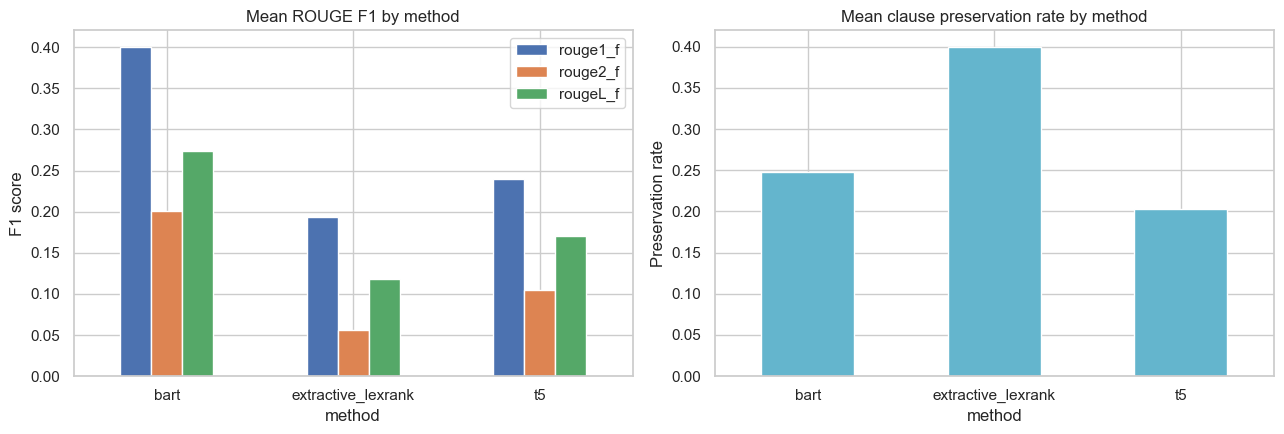

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

means = df_comparison.groupby("method")[["rouge1_f", "rouge2_f", "rougeL_f"]].mean()
means.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Mean ROUGE F1 by method")
axes[0].set_ylabel("F1 score")

df_comparison.groupby("method")["clause_preservation_rate"].mean().plot(kind="bar", ax=axes[1], color="#64B5CD", rot=0)
axes[1].set_title("Mean clause preservation rate by method")
axes[1].set_ylabel("Preservation rate")

plt.tight_layout()
plt.show()